# خوشه‌بندی مشتریان بانک
بخش‌بندی ۸۰ مشتری بر اساس رفتار مالی با K-Means، Hierarchical و GMM

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
import warnings; warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi']=100
df=pd.read_excel('../workbook.xlsx',sheet_name=0)
# نام‌های کوتاه انگلیسی برای نمودارها
en={'سن':'age','سابقه_مشتری_ماه':'tenure_m','درآمد_ماهانه_تخمینی_میلیون_تومان':'income','متوسط_ورودی_ماهانه_میلیون_تومان':'inflow',
'میانگین_مانده_جاری_میلیون_تومان':'current_bal','میانگین_مانده_پس‌انداز_میلیون_تومان':'savings_bal','تعداد_تراکنش_ماهانه':'txn_cnt',
'هزینه_خرید_ماهانه_میلیون_تومان':'spend','تعداد_ورود_اپ_ماهانه':'app_logins','تعداد_مراجعه_شعبه_سالانه':'branch_visits',
'تعداد_محصولات_فعال':'products','مانده_تسهیلات_میلیون_تومان':'loan_bal','مبلغ_قسط_ماهانه_میلیون_تومان':'installment',
'تعداد_اقساط_معوق_۱۲ماه':'late_pay','تعداد_روز_غیرفعالی_حساب':'inactive_days','تعداد_تراکنش_ناموفق_سالانه':'failed_txn',
'استفاده_بانکداری_اینترنتی':'internet_bank','شناسه_مشتری':'id','منطقه':'region','وضعیت_اشتغال':'job'}
df=df.rename(columns=en); print(df.shape); df.describe().T

(80, 20)


,count,mean,std,min,25%,50%,75%,max
age,80.0,43.512500,17.391977,18.00,28.0000,39.000,59.0000,79.00
tenure_m,80.0,94.262500,89.098117,0.00,29.7500,66.500,129.7500,349.00
income,72.0,21.791250,24.662854,1.95,6.3850,14.230,27.2900,130.13
inflow,80.0,23.300125,28.469970,0.91,6.7850,13.175,30.3025,156.31
current_bal,80.0,29.392625,60.576743,0.85,4.1625,12.830,22.1900,349.19
savings_bal,80.0,42.445000,135.805323,0.34,4.0325,9.880,25.9025,1136.02
txn_cnt,80.0,37.750000,27.972636,0.00,12.0000,34.000,59.5000,111.00
spend,80.0,12.587375,25.429652,0.30,2.6850,4.455,13.2025,199.21
app_logins,80.0,25.762500,22.122355,0.00,7.0000,21.000,34.0000,87.00
branch_visits,80.0,14.000000,11.323774,0.00,4.0000,11.000,21.0000,36.00


## ۱. بررسی داده و مقادیر مفقود

In [2]:
print(df.isna().sum()[lambda s:s>0]); print(df.duplicated('id').sum(),'duplicate ids')
print(df.skew(numeric_only=True).round(2).to_string())

income    8
dtype: int64
0 duplicate ids
age              0.40
tenure_m         1.36
income           2.67
inflow           3.02
current_bal      4.04
savings_bal      7.00
txn_cnt          0.58
spend            5.51
app_logins       1.04
branch_visits    0.64
products         0.93
loan_bal         2.08
installment      2.62
late_pay         3.73
inactive_days   -0.13
failed_txn       2.50
internet_bank   -0.20


## ۲. پیش‌پردازش و مهندسی ویژگی
مقدار مفقود درآمد با median پر می‌شود. ستون‌های چوله با `log1p` تبدیل و سپس استانداردسازی می‌شوند. شناسه و متغیرهای دسته‌ای (منطقه، اشتغال) وارد خوشه‌بندی نمی‌شوند و فقط برای پروفایل‌سازی استفاده می‌شوند.

log1p on: ['tenure_m', 'income', 'inflow', 'current_bal', 'savings_bal', 'spend', 'app_logins', 'loan_bal', 'installment', 'late_pay', 'failed_txn', 'dti', 'fail_rate']


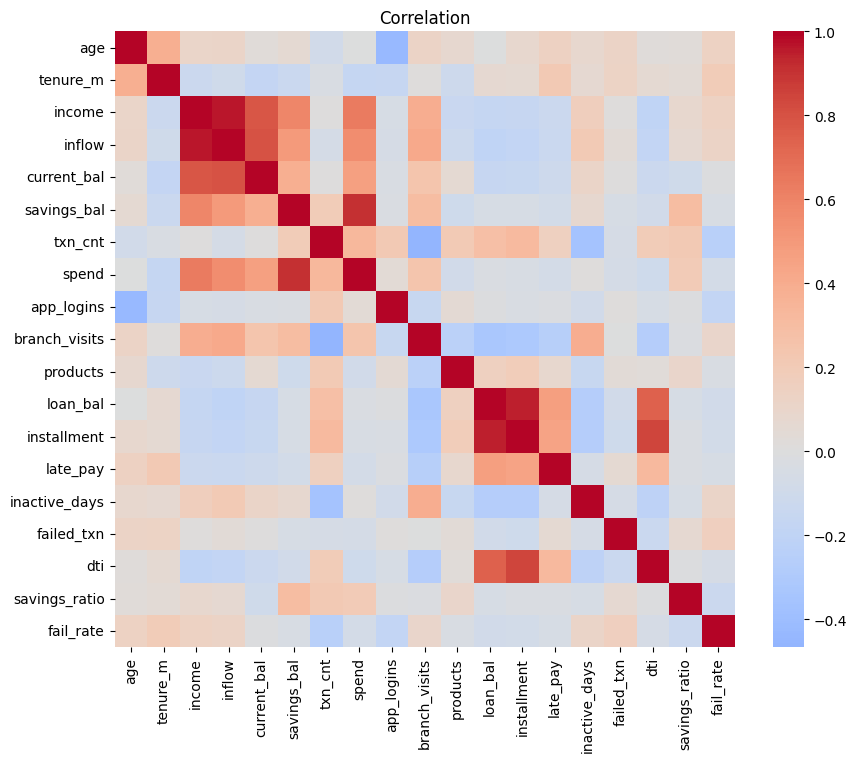

In [3]:
d=df.copy()
d['income']=d['income'].fillna(d['income'].median())
d['dti']=d['installment']/(d['income']+1)          # نسبت قسط به درآمد
d['savings_ratio']=d['savings_bal']/(d['savings_bal']+d['current_bal']+1e-6)
d['fail_rate']=d['failed_txn']/(d['txn_cnt']*12+1)
feats=['age','tenure_m','income','inflow','current_bal','savings_bal','txn_cnt','spend','app_logins','branch_visits',
       'products','loan_bal','installment','late_pay','inactive_days','failed_txn','dti','savings_ratio','fail_rate']
X=d[feats].copy()
skewed=[c for c in X if X[c].skew()>1 and X[c].min()>=0]; print('log1p on:',skewed)
X[skewed]=np.log1p(X[skewed])
Xs=StandardScaler().fit_transform(X)
corr=d[feats].corr(); plt.figure(figsize=(10,8)); sns.heatmap(corr,cmap='coolwarm',center=0); plt.title('Correlation'); plt.show()

## ۳. انتخاب تعداد خوشه (k)

,inertia,silhouette,DB,CH
k,,,,
2,1240.416,0.193,1.764,17.581
3,1085.608,0.138,1.994,15.405
4,962.629,0.158,1.786,14.668
5,887.165,0.141,1.770,13.375
6,815.315,0.160,1.567,12.792
7,774.605,0.155,1.612,11.708
8,725.968,0.146,1.626,11.250


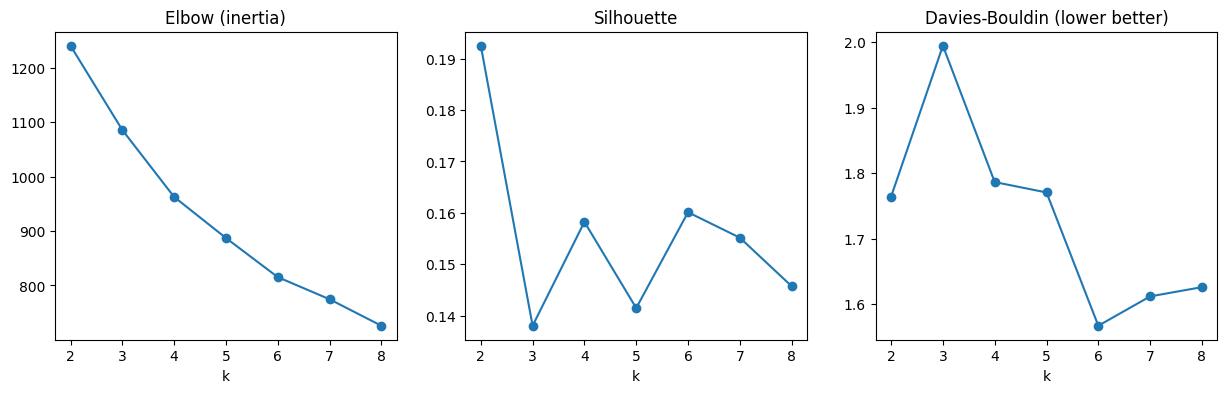

In [4]:
rows=[]
for k in range(2,9):
    km=KMeans(k,n_init=20,random_state=42).fit(Xs); l=km.labels_
    rows.append(dict(k=k,inertia=km.inertia_,silhouette=silhouette_score(Xs,l),DB=davies_bouldin_score(Xs,l),CH=calinski_harabasz_score(Xs,l)))
m=pd.DataFrame(rows).set_index('k'); display(m.round(3))
fig,ax=plt.subplots(1,3,figsize=(15,4))
m.inertia.plot(marker='o',ax=ax[0],title='Elbow (inertia)'); m.silhouette.plot(marker='o',ax=ax[1],title='Silhouette'); m.DB.plot(marker='o',ax=ax[2],title='Davies-Bouldin (lower better)')
plt.show()

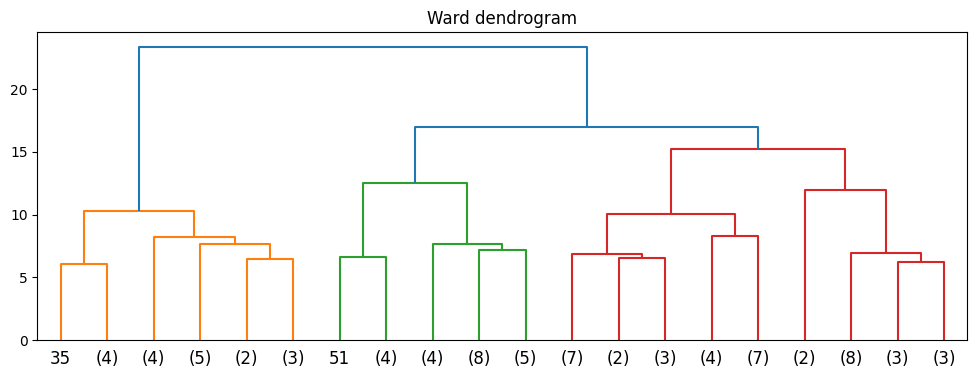

In [5]:
from scipy.cluster.hierarchy import linkage,dendrogram
plt.figure(figsize=(12,4)); dendrogram(linkage(Xs,'ward'),truncate_mode='lastp',p=20); plt.title('Ward dendrogram'); plt.show()

## ۴. مقایسه الگوریتم‌ها

In [6]:
K=int(input_k) if 'input_k' in globals() else 4
res={}
res['KMeans']=KMeans(K,n_init=50,random_state=42).fit_predict(Xs)
res['Hierarchical']=AgglomerativeClustering(K,linkage='ward').fit_predict(Xs)
res['GMM']=GaussianMixture(K,covariance_type='diag',n_init=10,random_state=42).fit(Xs).predict(Xs)
cmp=pd.DataFrame({n:dict(silhouette=silhouette_score(Xs,l),DB=davies_bouldin_score(Xs,l),CH=calinski_harabasz_score(Xs,l),sizes=np.bincount(l).tolist()) for n,l in res.items()}).T
display(cmp)
print('ARI KMeans vs Hier:',round(adjusted_rand_score(res['KMeans'],res['Hierarchical']),3),' KMeans vs GMM:',round(adjusted_rand_score(res['KMeans'],res['GMM']),3))
# پایداری K-Means با seedهای مختلف
base=res['KMeans']; print('stability ARI:',np.mean([adjusted_rand_score(base,KMeans(K,n_init=10,random_state=s).fit_predict(Xs)) for s in range(20)]).round(3))

,silhouette,DB,CH,sizes
KMeans,0.15976,1.751963,14.704808,"[21, 16, 32, 11]"
Hierarchical,0.136741,1.865779,13.613678,"[22, 19, 16, 23]"
GMM,0.060789,1.788256,8.167157,"[1, 54, 15, 10]"


ARI KMeans vs Hier: 0.539  KMeans vs GMM: 0.342


stability ARI: 0.825


## ۵. مدل نهایی (K-Means) و نمایش PCA

explained var [0.263 0.157]


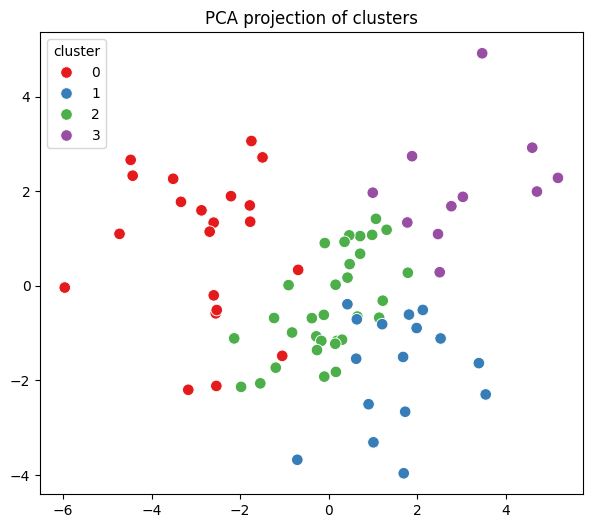

,PC1,PC2
dti,-0.34,0.21
installment,-0.31,0.26
loan_bal,-0.30,0.23
late_pay,-0.22,0.16
products,-0.09,0.11
txn_cnt,-0.09,0.41
app_logins,-0.07,0.24
tenure_m,-0.04,-0.05
age,0.02,-0.05
savings_ratio,0.07,0.19


In [7]:
d['cluster']=res['KMeans']
p=PCA(2).fit(Xs); Z=p.transform(Xs); print('explained var',p.explained_variance_ratio_.round(3))
plt.figure(figsize=(7,6)); sns.scatterplot(x=Z[:,0],y=Z[:,1],hue=d.cluster,palette='Set1',s=70); plt.title('PCA projection of clusters'); plt.show()
ld=pd.DataFrame(p.components_.T,index=feats,columns=['PC1','PC2']); display(ld.round(2).sort_values('PC1'))

## ۶. پروفایل خوشه‌ها

cluster,0,1,2,3
n,21.00,16.00,32.00,11.00
age,43.43,53.88,39.41,40.55
tenure_m,107.24,112.38,92.41,48.55
income,10.70,25.00,12.23,60.63
inflow,9.70,30.48,13.36,67.74
current_bal,9.55,21.45,10.92,132.55
savings_bal,5.63,24.96,18.51,207.81
txn_cnt,46.48,5.88,41.25,57.27
spend,6.00,2.70,6.88,56.16
app_logins,24.52,3.56,35.56,31.91


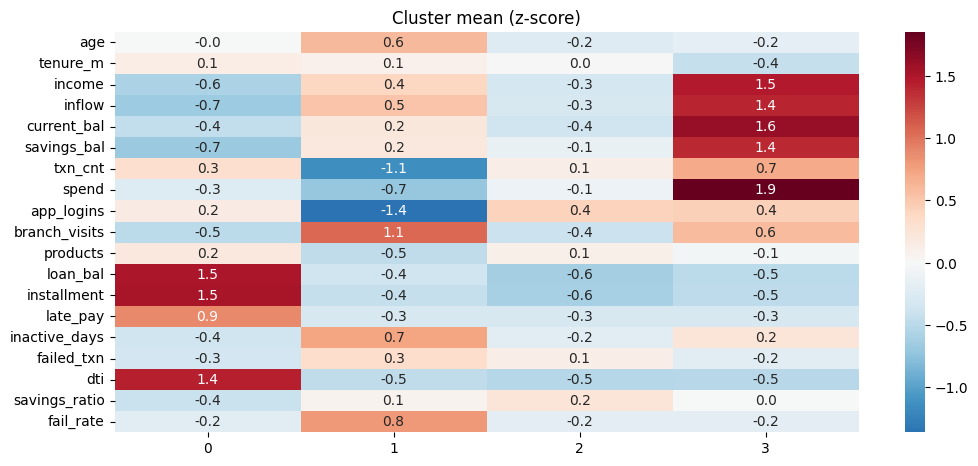

region,جنوب,شرق,شمال,غرب,مرکز
cluster,,,,,
0,0.24,0.14,0.24,0.24,0.14
1,0.06,0.31,0.06,0.31,0.25
2,0.19,0.16,0.31,0.19,0.16
3,0.27,0.18,0.09,0.18,0.27


job,بازنشسته,حقوق‌بگیر,خوداشتغال,دانشجو,سایر
cluster,,,,,
0,0.14,0.43,0.19,0.05,0.19
1,0.31,0.38,0.19,0.00,0.12
2,0.09,0.41,0.22,0.22,0.06
3,0.18,0.45,0.36,0.00,0.00


In [8]:
prof=d.groupby('cluster')[feats].mean().round(2); prof.insert(0,'n',d.cluster.value_counts().sort_index()); display(prof.T)
z=pd.DataFrame(Xs,columns=feats).groupby(d.cluster.values).mean()
plt.figure(figsize=(12,4+K*0.3)); sns.heatmap(z.T,cmap='RdBu_r',center=0,annot=True,fmt='.1f'); plt.title('Cluster mean (z-score)'); plt.show()
display(pd.crosstab(d.cluster,d.region,normalize='index').round(2)); display(pd.crosstab(d.cluster,d.job,normalize='index').round(2))

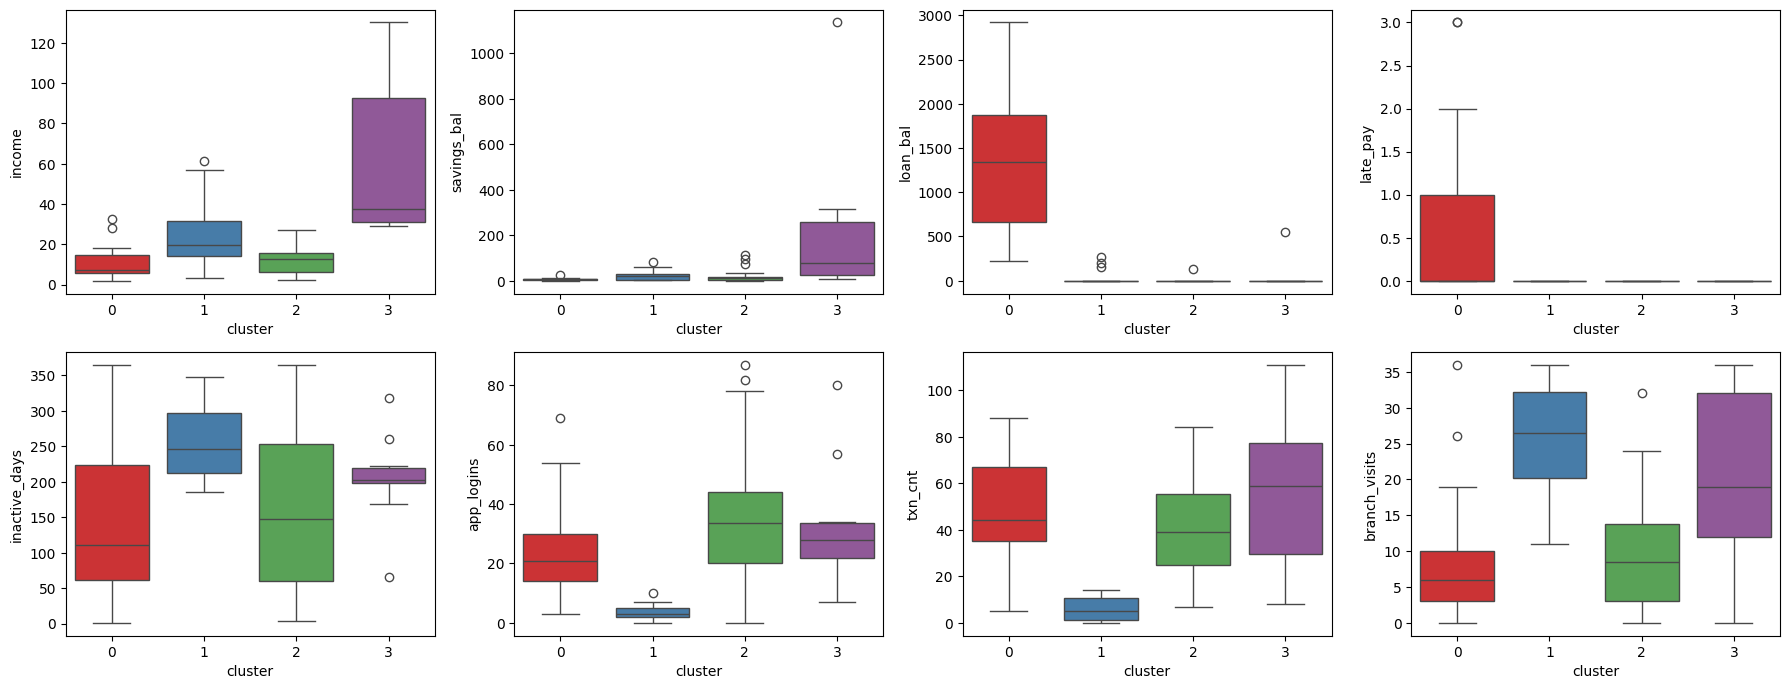

In [9]:
top=['income','savings_bal','loan_bal','late_pay','inactive_days','app_logins','txn_cnt','branch_visits']
fig,ax=plt.subplots(2,4,figsize=(18,7))
for a,c in zip(ax.ravel(),top): sns.boxplot(data=d,x='cluster',y=c,ax=a,palette='Set1')
plt.tight_layout(); plt.show()

## ۷. آزمون‌های اعتبارسنجی تکمیلی

### ۷-۱. پایداری با Bootstrap
در هر تکرار، نمونه bootstrap گرفته، K-Means روی آن آموزش داده و برچسب کل داده با نزدیک‌ترین مرکز تعیین می‌شود؛ سپس با خوشه‌بندی اصلی با ARI مقایسه می‌شود. این کار برای k=2..6 انجام شد.

,mean_ARI,sd,p5
2,0.679,0.375,-0.031
3,0.482,0.178,0.281
4,0.545,0.168,0.307
5,0.515,0.117,0.343
6,0.516,0.120,0.329


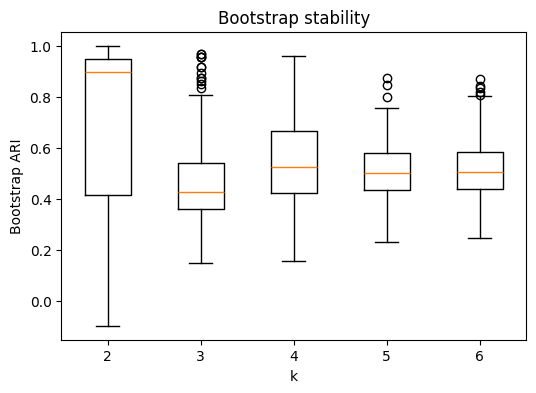

In [10]:
rng=np.random.RandomState(0); stab={}
for k in range(2,7):
    base=KMeans(k,n_init=20,random_state=42).fit_predict(Xs); sc=[]
    for b in range(200):
        idx=rng.choice(len(Xs),len(Xs),replace=True)
        km=KMeans(k,n_init=5,random_state=b).fit(Xs[idx]); sc.append(adjusted_rand_score(base,km.predict(Xs)))
    stab[k]=sc
st=pd.DataFrame({k:dict(mean_ARI=np.mean(v),sd=np.std(v),p5=np.percentile(v,5)) for k,v in stab.items()}).T.round(3); display(st)
plt.figure(figsize=(6,4)); plt.boxplot(list(stab.values()),labels=list(stab.keys())); plt.xlabel('k'); plt.ylabel('Bootstrap ARI'); plt.title('Bootstrap stability'); plt.show()

### ۷-۲. آزمون معناداری تفاوت خوشه‌ها (Kruskal-Wallis) و اندازه اثر
اندازه اثر: ε² = H/(n-1)، و اصلاح Benjamini-Hochberg برای مقایسه چندگانه. توجه: چون خوشه‌ها از همین ویژگی‌ها ساخته شده‌اند، این آزمون جنبه توصیفی دارد و نه استنباطی (circularity).

In [11]:
from scipy.stats import kruskal, chi2_contingency
from statsmodels.stats.multitest import multipletests
r=[]
for c in feats:
    H,p=kruskal(*[d.loc[d.cluster==g,c] for g in range(K)]); r.append((c,H,p,H/(len(d)-1)))
kw=pd.DataFrame(r,columns=['feature','H','p','epsilon2']).set_index('feature')
kw['p_BH']=multipletests(kw.p,method='fdr_bh')[1]; kw=kw.sort_values('epsilon2',ascending=False); display(kw.round(4))
for c in ['region','job']:
    ct=pd.crosstab(d.cluster,d[c]); print(c,'chi2 p=',round(chi2_contingency(ct)[1],3))

,H,p,epsilon2,p_BH
feature,,,,
dti,66.8967,0.0000,0.8468,0.0000
loan_bal,65.4495,0.0000,0.8285,0.0000
installment,64.6211,0.0000,0.8180,0.0000
inflow,35.6114,0.0000,0.4508,0.0000
income,34.1988,0.0000,0.4329,0.0000
spend,34.0113,0.0000,0.4305,0.0000
app_logins,33.8133,0.0000,0.4280,0.0000
txn_cnt,33.4809,0.0000,0.4238,0.0000
fail_rate,31.2586,0.0000,0.3957,0.0000


region chi2 p= 0.633
job chi2 p= 0.208


### ۷-۳. مقایسه با روش پایه RFM
یک بخش‌بندی RFM-مانند (Recency=روز غیرفعالی معکوس، Frequency=تراکنش، Monetary=مانده کل) با K-Means و همان k ساخته و با خوشه‌بندی اصلی مقایسه می‌شود. معیار مشترک: Silhouette روی کل فضای ویژگی‌ها.

In [12]:
rfm=pd.DataFrame({'R':-np.log1p(d.inactive_days),'F':np.log1p(d.txn_cnt),'M':np.log1p(d.current_bal+d.savings_bal)})
Rs=StandardScaler().fit_transform(rfm); lr=KMeans(K,n_init=50,random_state=42).fit_predict(Rs)
print('RFM sizes',np.bincount(lr),' ARI vs main:',round(adjusted_rand_score(d.cluster,lr),3))
print('Silhouette on full features -> main:',round(silhouette_score(Xs,d.cluster),3),' RFM:',round(silhouette_score(Xs,lr),3))
print('Silhouette on RFM space     -> main:',round(silhouette_score(Rs,d.cluster),3),' RFM:',round(silhouette_score(Rs,lr),3))
d['rfm']=lr; display(d.groupby('rfm')[['late_pay','loan_bal','savings_bal','income','inactive_days']].mean().round(2))

RFM sizes [38 12 13 17]  ARI vs main: 0.24
Silhouette on full features -> main: 0.16  RFM: 0.039
Silhouette on RFM space     -> main: 0.081  RFM: 0.362


,late_pay,loan_bal,savings_bal,income,inactive_days
rfm,,,,,
0,0.29,453.69,9.15,11.84,184.79
1,0.00,46.26,215.24,52.17,228.42
2,0.15,623.39,14.27,14.55,22.38
3,0.06,93.63,16.43,24.57,257.00


### ۷-۴. تحلیل حساسیت: پرت‌ها، مقیاس‌گذاری و زیرمجموعه ویژگی‌ها
بررسی می‌کنیم آیا ساختار خوشه‌ها با تغییر تنظیمات حفظ می‌شود (ARI نسبت به مدل اصلی).

In [13]:
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import IsolationForest
base=d.cluster.values; out={}
Xr=RobustScaler().fit_transform(X); out['RobustScaler']=KMeans(K,n_init=50,random_state=42).fit_predict(Xr)
core=['age','tenure_m','income','inflow','current_bal','savings_bal','txn_cnt','spend','app_logins','branch_visits','products','loan_bal','installment','late_pay','inactive_days','failed_txn']
Xc=StandardScaler().fit_transform(X[core]); out['No engineered ratios']=KMeans(K,n_init=50,random_state=42).fit_predict(Xc)
Xp=PCA(0.85).fit_transform(Xs); out['PCA 85% var']=KMeans(K,n_init=50,random_state=42).fit_predict(Xp)
print('PCA comps for 85%:',Xp.shape[1])
iso=IsolationForest(contamination=0.1,random_state=0).fit_predict(Xs); keep=iso==1; print('outliers removed:',(~keep).sum())
km=KMeans(K,n_init=50,random_state=42).fit(Xs[keep]); out['Without outliers (pred. all)']=km.predict(Xs)
sens=pd.DataFrame({n:dict(ARI_vs_main=adjusted_rand_score(base,l),silhouette=silhouette_score(Xs,l)) for n,l in out.items()}).T.round(3); display(sens)
print('outlier cluster membership:'); print(pd.Series(base[~keep]).value_counts().sort_index().to_dict())

PCA comps for 85%: 9


outliers removed: 8


,ARI_vs_main,silhouette
RobustScaler,0.055,0.023
No engineered ratios,0.939,0.160
PCA 85% var,0.773,0.151
Without outliers (pred. all),0.771,0.146


outlier cluster membership:
{0: 6, 3: 2}


### ۷-۵. اعتبارسنجی بیرونی-شبه‌ای: آیا خوشه‌ها با ریسک و غیرفعالی مرتبط‌اند؟
متغیرهای `late_pay` و `inactive_days` (و مشتقات مستقیم آن‌ها) را از ورودی خوشه‌بندی حذف کرده، دوباره خوشه‌بندی می‌کنیم و بررسی می‌کنیم خوشه‌ها همچنان این دو متغیر را تفکیک می‌کنند یا نه. این آزمون فقط یک شاهد غیرمستقیم است، نه اعتبارسنجی با برچسب واقعی.

In [14]:
ex=['late_pay','inactive_days']; cols=[c for c in feats if c not in ex]
Xh=StandardScaler().fit_transform(X[cols]); lh=KMeans(K,n_init=50,random_state=42).fit_predict(Xh)
print('ARI vs main:',round(adjusted_rand_score(base,lh),3))
for c in ex:
    H,p=kruskal(*[d.loc[lh==g,c] for g in range(K)]); print(c,'Kruskal H=%.2f p=%.4f'%(H,p))
print(d.assign(h=lh).groupby('h')[ex].mean().round(2))

ARI vs main: 0.963
late_pay Kruskal H=24.58 p=0.0000
inactive_days Kruskal H=9.20 p=0.0268
   late_pay  inactive_days
h                         
0      0.00         242.24
1      0.67         142.90
2      0.00         205.18
3      0.00         162.81


## ۸. خروجی

In [15]:
d[['id','cluster']+feats].to_csv('clustered_customers.csv',index=False); m.to_csv('k_selection.csv'); prof.to_csv('cluster_profiles.csv'); print('saved')

saved
